# Avance 5 — Modelos de ensamble y selección del modelo final
**Proyecto Integrador · Equipo 54 · Fresas Donna y Dream**

**Integrantes:** Fanny Betsabé Fuentes Reyes, Juan Luis Ramírez Sánchez y Joaquín Rincón Pérez.

Esta libreta continúa directamente el **Avance 4**. Conserva la reconstrucción experimental, el split por parcela, la ingeniería temporal, la selección supervisada dentro del pipeline y la métrica principal **RMSE (g/planta)**.

### Objetivo del avance
1. Comparar los **seis modelos individuales** evaluados en la fase previa contra estrategias de ensamble.
2. Construir ensambles **homogéneos** (Bagging, Random Forest, Extra Trees) y **heterogéneos** (Voting y Stacking).
3. Reutilizar **KNN y Ridge**, los dos modelos individuales priorizados en el Avance 4, como modelos base de Voting y Stacking, reoptimizándolos exclusivamente con datos de entrenamiento.
4. Optimizar hiperparámetros sin consultar el holdout.
5. Sintetizar RMSE, MAE, R², estabilidad y tiempo de entrenamiento en una tabla única.
6. Elegir un modelo final con un criterio explícito de generalización, estabilidad y costo computacional.
7. Interpretar el modelo elegido mediante gráficos apropiados para **regresión**.

> **Alcance:** el análisis es retrospectivo. Con 32 observaciones y 16 parcelas, los resultados son exploratorios y no deben interpretarse como evidencia causal.


In [1]:
# Librerías y configuración general
from pathlib import Path
import re, warnings, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from scipy.stats import spearmanr, skew, shapiro, levene, f_oneway, kruskal
from statsmodels.stats.multitest import multipletests

pd.set_option('display.max_columns', 160)
pd.set_option('display.width', 210)
sns.set_theme(style='whitegrid', palette='deep')

SEED = 54
np.random.seed(SEED)

# ============================================================
# EJECUCIÓN LOCAL
# El notebook y los nueve archivos Excel deben estar en la misma carpeta.
# ============================================================
HERE = Path.cwd().resolve()
ROOT = HERE
BASE_DIR = HERE

OUT = HERE / 'outputs' / 'avance5_modelado'
FIG = OUT / 'figuras'
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

FILES = {
    'antiox': 'Antiox_data.xlsx',
    'sampling': 'Sampling May 2023.xlsx',
    'harvests': 'harvests.xlsx',
    'soil': 'Dataset_final_suelo.xlsx',
    'leaf': 'Dataset_final_leaf.xlsx',
    'poly_raw': 'alldata_polyphenols.xlsx',
    'anth_raw': 'Anthocyanins.xlsx',
    'vitc_raw': 'VitC_MarinaPerez.xlsx',
    'poly_table': 'Table polyphenols.xlsx',
}

missing_files = [name for name in FILES.values() if not (BASE_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        f'Faltan archivos en {BASE_DIR}: ' + ', '.join(missing_files)
    )

print('Directorio de trabajo:', HERE)
print('Directorio de datos:', BASE_DIR)
print('Archivos originales detectados:', len(FILES))
print('Resultados:', OUT)


Directorio de trabajo: /mnt/data
Directorio de datos: /mnt/data
Archivos originales detectados: 9
Resultados: /mnt/data/outputs/avance5_modelado


In [2]:
SHEETS = {
    'antiox': {'Antiox_data': None},
    'sampling': {'all_data': None},
    'harvests': {'harvests': None, 'productions_kg': None},
    'soil': {'Final': None},
    'leaf': {'Isotopes': None, 'RGB': None, 'Nitrates': None, 'Nutrients': 1},
    'poly_raw': {'alldata_polyphenols': None, 'data_polyphenols': None},
    'anth_raw': {'Cyanidin gluc': None, 'Pelargonidin gluc': None, 'Pelargonidin rutin': None},
    'vitc_raw': {'Hoja3': None},
}

inventory=[]
for key, name in FILES.items():
    book = pd.ExcelFile(BASE_DIR / name)
    for sheet in book.sheet_names:
        inventory.append({'Fuente':key,'Archivo':name,'Hoja':sheet})
    if key in SHEETS:
        for sheet in SHEETS[key]:
            if sheet not in book.sheet_names:
                raise ValueError(f'{name}: falta hoja {sheet!r}. Hojas disponibles: {book.sheet_names}')

inventory_df = pd.DataFrame(inventory)
raw={}
for key, sheets in SHEETS.items():
    for sheet, header in sheets.items():
        args={'sheet_name':sheet}
        if header is not None:
            args['header']=header
        df=pd.read_excel(BASE_DIR / FILES[key], **args)
        df.columns=[str(c).strip() for c in df.columns]
        raw[(key,sheet)] = df
        inventory_df.loc[(inventory_df.Fuente==key)&(inventory_df.Hoja==sheet),'Filas']=len(df)
        inventory_df.loc[(inventory_df.Fuente==key)&(inventory_df.Hoja==sheet),'Columnas']=df.shape[1]

display(inventory_df.loc[inventory_df['Filas'].notna(), ['Fuente','Archivo','Hoja','Filas','Columnas']])


,Fuente,Archivo,Hoja,Filas,Columnas
0,antiox,Antiox_data.xlsx,Antiox_data,32.0,27.0
8,sampling,Sampling May 2023.xlsx,all_data,32.0,19.0
10,harvests,harvests.xlsx,harvests,608.0,13.0
12,harvests,harvests.xlsx,productions_kg,32.0,18.0
16,soil,Dataset_final_suelo.xlsx,Final,32.0,15.0
18,leaf,Dataset_final_leaf.xlsx,Nitrates,65.0,14.0
19,leaf,Dataset_final_leaf.xlsx,Isotopes,64.0,9.0
20,leaf,Dataset_final_leaf.xlsx,RGB,96.0,8.0
21,leaf,Dataset_final_leaf.xlsx,Nutrients,64.0,28.0
22,poly_raw,alldata_polyphenols.xlsx,alldata_polyphenols,64.0,20.0


In [3]:
antiox_raw = raw[('antiox','Antiox_data')]
fruit_raw = raw[('sampling','all_data')]
harvest_raw = raw[('harvests','harvests')]
yield_raw = raw[('harvests','productions_kg')]
soil_raw = raw[('soil','Final')]
iso_raw = raw[('leaf','Isotopes')]
rgb_raw = raw[('leaf','RGB')]
nitr_raw = raw[('leaf','Nitrates')]
nut_raw = raw[('leaf','Nutrients')].copy()
nut_raw = nut_raw.loc[:, ~nut_raw.columns.astype(str).str.startswith('Unnamed')]
nitr_raw = nitr_raw.loc[nitr_raw['Parcel/Plot'].notna()].copy()

CORE = {
    'Antioxidantes':antiox_raw, 'Calidad fruto':fruit_raw, 'Producción':yield_raw,
    'Cosechas por fecha':harvest_raw, 'Suelo':soil_raw, 'Hoja isótopos':iso_raw,
    'Hoja nitratos':nitr_raw, 'Hoja nutrientes':nut_raw, 'Hoja RGB':rgb_raw
}

def describe_source(name, df):
    return {
        'Fuente':name, 'Filas':len(df), 'Columnas':df.shape[1],
        'Numéricas':df.select_dtypes(include=np.number).shape[1],
        'NA totales':int(df.isna().sum().sum()),
        'Filas idénticas':int(df.duplicated().sum())
    }

source_profile = pd.DataFrame([describe_source(k,d) for k,d in CORE.items()])
display(source_profile)


,Fuente,Filas,Columnas,Numéricas,NA totales,Filas idénticas
0,Antioxidantes,32,27,22,12,0
1,Calidad fruto,32,19,16,14,0
2,Producción,32,18,12,99,0
3,Cosechas por fecha,608,13,8,912,0
4,Suelo,32,15,13,0,0
5,Hoja isótopos,64,9,4,0,0
6,Hoja nitratos,64,14,9,0,0
7,Hoja nutrientes,64,24,20,0,0
8,Hoja RGB,96,8,4,0,0


In [4]:
# Estandarización de tratamientos.
SOIL_TO_T = {
    'COMPOST':'T1', 'N-RICH':'T2', 'NRICH':'T2',
    'RCW-HD':'T3','RWC-HD':'T3','WR-HD':'T3','RCWHD':'T3',
    'RCW-LD':'T4','RWC-LD':'T4','WR-LD':'T4','RCWLD':'T4'
}
# IMPORTANTE: en todos los gráficos/tablas visibles se usarán nombres, no códigos.
T_TO_NAME = {'T1':'Compost', 'T2':'N-rich', 'T3':'RCW-HD', 'T4':'RCW-LD'}
TREATMENT_ORDER = ['Compost','N-rich','RCW-HD','RCW-LD']

def clean_cv(s):
    v=s.astype('string').str.strip().str.upper()
    return v.map({'DO':'Donna','DONA':'Donna','DONNA':'Donna','DR':'Dream','DREAM':'Dream'})

def clean_code(s):
    return s.astype('string').str.strip().str.upper().str.replace(r'\s+','',regex=True)

def require_cols(df, cols, label):
    missing=set(cols)-set(df.columns)
    if missing:
        raise KeyError(f'{label}: columnas no encontradas: {sorted(missing)}; disponibles={list(df.columns)}')

KEYS=['Cultivar','Treatment','Replicate']

def make_keys(df, cv, tr, rep, label):
    require_cols(df,[cv,tr,rep],label)
    return pd.DataFrame({
        'Cultivar':clean_cv(df[cv]),
        'Treatment':clean_code(df[tr]),
        'Replicate':clean_code(df[rep])
    }, index=df.index)

def check_unique(df, keys, label):
    na=df[keys].isna().any(axis=1)
    dup=df.duplicated(keys,keep=False)
    if na.any() or dup.any():
        display(df.loc[na|dup,keys].head(20))
        raise ValueError(f'{label}: claves nulas o duplicadas; no se realizará unión insegura.')

display(pd.DataFrame([{'Código original':k,'Tratamiento mostrado':v} for k,v in T_TO_NAME.items()]))


,Código original,Tratamiento mostrado
0,T1,Compost
1,T2,N-rich
2,T3,RCW-HD
3,T4,RCW-LD


In [5]:
# Construcción de las fuentes principales en Cultivar × Treatment × Replicate.
ant = make_keys(antiox_raw,'cultivar','Treatment','Replicate','Antiox_data')
for c in antiox_raw.columns:
    if c not in ['Sample','cultivar','Treatment','Replicate','New_block']:
        ant[c]=pd.to_numeric(antiox_raw[c],errors='coerce')
check_unique(ant,KEYS,'Antioxidantes')

fruit = make_keys(fruit_raw,'Cv','Treatment','Repl','Sampling/all_data')
for c in ['Weight','Hydrat','Firm','Hue','Chroma','BRIX','Acidity','GA','GGA','CSI']:
    if c in fruit_raw:
        fruit['fruit_'+c]=pd.to_numeric(fruit_raw[c],errors='coerce')
check_unique(fruit,KEYS,'Calidad del fruto')

yld = make_keys(yield_raw,'Cv','Treatment','Repl','Producción')
for c in ['Com Ton/ha','No com Ton/ha','Nº de plantes','g/planta']:
    if c in yield_raw:
        yld['yield_'+c]=pd.to_numeric(yield_raw[c],errors='coerce')
check_unique(yld,KEYS,'Producción')

sets_keys={name:set(map(tuple,df[KEYS].to_numpy())) for name,df in {'Antiox':ant,'Fruto':fruit,'Producción':yld}.items()}
assert sets_keys['Antiox']==sets_keys['Fruto']==sets_keys['Producción'], 'Las claves de las fuentes principales no coinciden.'

# Suelo 2023: una observación por Treatment × Replicate.
require_cols(soil_raw,['Treatment','Block','Year'],'Suelo/Final')
soil23=soil_raw.loc[pd.to_numeric(soil_raw['Year'],errors='coerce').eq(2023)].copy()
soil_t_raw=clean_code(soil23['Treatment']).str.replace('_','-',regex=False)
soil=pd.DataFrame({'Treatment':soil_t_raw.map(SOIL_TO_T), 'Replicate':clean_code(soil23['Block'])}, index=soil23.index)
for c in soil23.columns:
    if c not in ['Treatment','Year','Block','Plot']:
        soil['soil_'+c]=pd.to_numeric(soil23[c],errors='coerce')
if soil.Treatment.isna().any():
    raise ValueError('Existen tratamientos de suelo sin mapear: '+str(soil23.loc[soil.Treatment.isna(),'Treatment'].unique()))
check_unique(soil,['Treatment','Replicate'],'Suelo 2023')

# Hojas: réplicas técnicas en la misma unidad/fecha se resumen por media.
def pivot_leaf(df,cv,tr,rep,time,measures,prefix,label):
    require_cols(df,[cv,tr,rep]+measures,label)
    k=make_keys(df,cv,tr,rep,label)
    k['Time']=pd.Series(time,index=df.index).astype('string').str.strip()
    for c in measures:
        k[c]=pd.to_numeric(df[c],errors='coerce')
    piv=k.pivot_table(index=KEYS, columns='Time', values=measures, aggfunc='mean')
    piv.columns=[f'{prefix}_{str(c)}_{str(t)}' for c,t in piv.columns]
    return piv.reset_index()

iso_t=iso_raw['Date'].astype('string').str.extract('(March|May)',expand=False)
leaf_iso=pivot_leaf(iso_raw,'Cv','Treatment','Replicate',iso_t,
                    [c for c in ['%N','d13C'] if c in iso_raw], 'leaf_iso','Isotopes')

nut_vars=[c for c in nut_raw.columns if c not in ['Sample','Parcel/Plot','Cv','Treatment','Repl','Time']
          and pd.api.types.is_numeric_dtype(nut_raw[c])]
leaf_nut=pivot_leaf(nut_raw,'Cv','Treatment','Repl',nut_raw['Time'],nut_vars,'leaf_nut','Nutrients')
leaf_no3=pivot_leaf(nitr_raw,'Cv','Treatment','Repl',nitr_raw['Time'],
                    [c for c in ['mg NO3-/ g DW','mg NO3-/ 100 mg DW'] if c in nitr_raw],
                    'leaf_no3','Nitrates')
leaf_rgb=pivot_leaf(rgb_raw,'Cv','Treatment','Repl',rgb_raw['Time'],
                    [c for c in ['GA','GGA','CSI'] if c in rgb_raw], 'leaf_rgb','RGB')

# Unión maestra.
ana=ant.merge(fruit,on=KEYS,how='outer',validate='one_to_one',indicator='_source_fruit')
ana=ana.merge(yld,on=KEYS,how='outer',validate='one_to_one',indicator='_source_yield')
ana=ana.merge(soil,on=['Treatment','Replicate'],how='left',validate='many_to_one',indicator='_source_soil')
for x in [leaf_iso,leaf_nut,leaf_no3,leaf_rgb]:
    ana=ana.merge(x,on=KEYS,how='left',validate='one_to_one')

ana['Parcel_ID']=ana['Treatment'].astype(str)+'_'+ana['Replicate'].astype(str)
ana['Treatment_name']=ana['Treatment'].map(T_TO_NAME).fillna('Sin mapear')
ana['Cultivar_Treatment']=ana['Cultivar'].astype(str)+' · '+ana['Treatment_name'].astype(str)

assert not ana[KEYS].duplicated().any(), 'La unión generó llaves duplicadas.'
print('Filas analíticas:',len(ana))
print('Parcelas:',ana.Parcel_ID.nunique())
print('Variables numéricas:',len(ana.select_dtypes(include=np.number).columns))
print('Tratamientos visibles:',sorted(ana.Treatment_name.unique()))

if len(ana)!=32 or ana.Parcel_ID.nunique()!=16:
    warnings.warn('Cobertura distinta de 32 filas / 16 parcelas: revisar fuentes y llaves de unión.')


Filas analíticas: 32
Parcelas: 16
Variables numéricas: 100
Tratamientos visibles: ['Compost', 'N-rich', 'RCW-HD', 'RCW-LD']


In [6]:
# Bloques científicos.
design_cols=['Cultivar','Treatment','Treatment_name','Replicate','Parcel_ID','Cultivar_Treatment']
soil_cols=[c for c in ana if c.startswith('soil_') and pd.api.types.is_numeric_dtype(ana[c])]
leaf_nutrition_cols=[c for c in ana if c.startswith(('leaf_nut_','leaf_iso_','leaf_no3_')) and pd.api.types.is_numeric_dtype(ana[c])]
rgb_cols=[c for c in ana if c.startswith('leaf_rgb_') and pd.api.types.is_numeric_dtype(ana[c])]
production_cols=[c for c in ana if c.startswith('yield_') and pd.api.types.is_numeric_dtype(ana[c])]
rgb_duplicate_outcomes=[c for c in ['fruit_GA','fruit_GGA','fruit_CSI'] if c in ana.columns]
# GA/GGA/CSI del archivo de sampling se consideran indicadores de vegetación/RGB, no calidad fisicoquímica del fruto.
# Además, en el EDA previo se observó que duplican las mediciones RGB de mayo; se excluyen de outcomes para evitar relaciones innecesarias.
physchem_cols=[c for c in ana if c.startswith('fruit_') and pd.api.types.is_numeric_dtype(ana[c]) and c not in rgb_duplicate_outcomes]
nutritional_cols=[c for c in ant.columns if c not in KEYS and c in ana.columns and pd.api.types.is_numeric_dtype(ana[c])]

BLOCKS={
    'Diseño experimental':design_cols,
    'Suelo':soil_cols,
    'Hoja / nutrición':leaf_nutrition_cols,
    'Hoja / RGB-fisiología':rgb_cols,
    'Producción':production_cols,
    'Calidad fisicoquímica':physchem_cols,
    'Calidad nutricional / bioactivos':nutritional_cols,
}
block_summary=pd.DataFrame([{'Bloque':k,'Variables':len(v)} for k,v in BLOCKS.items()])
display(block_summary)

X_raw_cols=soil_cols+leaf_nutrition_cols+rgb_cols
outcome_families={
    'Producción':production_cols,
    'Fisicoquímica':physchem_cols,
    'Nutricional':nutritional_cols,
}

advantages = [
    'Diseño balanceado: 2 cultivares × 4 tratamientos × 4 réplicas.',
    'Múltiples capas del sistema: suelo, hoja, fisiología/RGB, producción y fruto.',
    'Mediciones temporales en suelo y hoja que permiten estudiar evolución.',
    'Resultados químicos y bioactivos suficientes para formular objetivos múltiples.'
]
limitations = [
    'n≈32 es pequeño frente al número de variables (p >> n).',
    'Algunas variables presentan faltantes y distribuciones sesgadas.',
    'Suelo se comparte por parcela; no todas las columnas son observaciones independientes.',
    'Treatment mezcla tipo de enmienda y práctica de labranza; no permite separar ambos efectos causalmente.',
    'Los modelos solo pueden generalizar razonablemente dentro de tratamientos/cultivares similares a los observados.'
]

display(Markdown('### Ventajas de la información\n' + '\n'.join([f'- {x}' for x in advantages])))
display(Markdown('### Limitaciones que condicionan el modelado\n' + '\n'.join([f'- {x}' for x in limitations])))

print('Columnas GA/GGA/CSI excluidas de calidad fisicoquímica por pertenecer a RGB/redundancia:', rgb_duplicate_outcomes)


,Bloque,Variables
0,Diseño experimental,6
1,Suelo,11
2,Hoja / nutrición,44
3,Hoja / RGB-fisiología,9
4,Producción,4
5,Calidad fisicoquímica,7
6,Calidad nutricional / bioactivos,22


### Ventajas de la información
- Diseño balanceado: 2 cultivares × 4 tratamientos × 4 réplicas.
- Múltiples capas del sistema: suelo, hoja, fisiología/RGB, producción y fruto.
- Mediciones temporales en suelo y hoja que permiten estudiar evolución.
- Resultados químicos y bioactivos suficientes para formular objetivos múltiples.

### Limitaciones que condicionan el modelado
- n≈32 es pequeño frente al número de variables (p >> n).
- Algunas variables presentan faltantes y distribuciones sesgadas.
- Suelo se comparte por parcela; no todas las columnas son observaciones independientes.
- Treatment mezcla tipo de enmienda y práctica de labranza; no permite separar ambos efectos causalmente.
- Los modelos solo pueden generalizar razonablemente dentro de tratamientos/cultivares similares a los observados.

Columnas GA/GGA/CSI excluidas de calidad fisicoquímica por pertenecer a RGB/redundancia: ['fruit_GA', 'fruit_GGA', 'fruit_CSI']


## 1. Diagnóstico de la tarea y calidad de los datos
**Regresión**, porque el rendimiento en gramos por planta es continuo. La exploración comprueba faltantes, duplicados, valores extremos y correlación entre predictores; los valores atípicos no se eliminan automáticamente. El análisis no pretende estimar causalidad ni realizar pronóstico anterior a la cosecha.

In [7]:
# Ingeniería temporal: baseline + delta, reutilizando la lógica de Avance 2.
def feature_builder(df):
    z=df.copy(); created={}; removed=[]; original=list(z.columns)

    for family in ['leaf_iso_','leaf_no3_','leaf_nut_']:
        may_cols=[c for c in original if c.startswith(family) and c.endswith('_May')]
        for may in may_cols:
            march=may[:-3]+'March'
            if march in z.columns:
                new='FE_delta_'+may.replace('_May','')
                z[new]=pd.to_numeric(z[may],errors='coerce')-pd.to_numeric(z[march],errors='coerce')
                created[new]=f'Cambio May - March; baseline conservado en {march}.'
                removed.append(may)

    rgb_metrics=sorted({c.rsplit('_',1)[0] for c in original if c.startswith('leaf_rgb_')})
    for base in rgb_metrics:
        dec,mar,may=base+'_December',base+'_March',base+'_May'
        if dec in z and mar in z:
            d1='FE_delta_'+base+'_March_minus_December'
            z[d1]=pd.to_numeric(z[mar],errors='coerce')-pd.to_numeric(z[dec],errors='coerce')
            created[d1]=f'Cambio March - December para {base}; December funciona como baseline.'
            removed.append(mar)
        if mar in z and may in z:
            d2='FE_delta_'+base+'_May_minus_March'
            z[d2]=pd.to_numeric(z[may],errors='coerce')-pd.to_numeric(z[mar],errors='coerce')
            created[d2]=f'Cambio May - March para {base}.'
            removed.append(may)

    removed=list(dict.fromkeys([c for c in removed if c in z.columns]))
    z=z.drop(columns=removed)
    return z,created,removed

ana_fe, derived, temporal_removed = feature_builder(ana)

# Control de disponibilidad temporal (el modo retrospectivo NO equivale a pronostico temprano).
PREDICTION_MODE = 'retrospectivo'  # 'temprano' solo tras verificar calendario de muestreo
CUTOFF_PERIOD = None  # December, March o May si PREDICTION_MODE='temprano'
PERIOD_ORDER = {'December': 0, 'March': 1, 'May': 2}

def latest_measurement_period(column):
    if 'May_minus_March' in column: return 'May'
    if 'March_minus_December' in column: return 'March'
    if column.startswith('FE_delta_leaf_'): return 'May'
    for period in PERIOD_ORDER:
        if column.endswith('_' + period): return period
    return None

if PREDICTION_MODE == 'temprano':
    if CUTOFF_PERIOD not in PERIOD_ORDER:
        raise ValueError('CUTOFF_PERIOD debe ser December, March o May.')
    excluded_temporal = [c for c in ana_fe.columns
                         if latest_measurement_period(c) is not None
                         and PERIOD_ORDER[latest_measurement_period(c)] > PERIOD_ORDER[CUTOFF_PERIOD]]
    ana_fe = ana_fe.drop(columns=excluded_temporal)
    print('Excluidas por corte temporal:', len(excluded_temporal))
    print('Advertencia: revisar tambien fechas reales de suelo y cosecha; el nombre no prueba disponibilidad.')
else:
    excluded_temporal = []
    print('Modo retrospectivo: asociaciones posteriores al cultivo; NO prediccion temprana.')

soil_fe=[c for c in ana_fe if c.startswith('soil_') and pd.api.types.is_numeric_dtype(ana_fe[c])]
leaf_fe=[c for c in ana_fe if (c.startswith(('leaf_nut_','leaf_iso_','leaf_no3_')) or c.startswith(('FE_delta_leaf_nut_','FE_delta_leaf_iso_','FE_delta_leaf_no3_'))) and pd.api.types.is_numeric_dtype(ana_fe[c])]
rgb_fe=[c for c in ana_fe if (c.startswith('leaf_rgb_') or c.startswith('FE_delta_leaf_rgb_')) and pd.api.types.is_numeric_dtype(ana_fe[c])]
X_fe_cols=list(dict.fromkeys(soil_fe+leaf_fe+rgb_fe))

work_cols=list(dict.fromkeys(['Cultivar','Treatment','Treatment_name','Replicate','Parcel_ID','Cultivar_Treatment'] + X_fe_cols + production_cols + physchem_cols + nutritional_cols))
work=ana_fe[work_cols].copy().replace([np.inf,-np.inf],np.nan)

print('Predictores originales suelo+hoja+RGB:',len(X_raw_cols))
print('Predictores después de FE temporal:',len(X_fe_cols))
print('Características delta creadas:',len(derived))
print('Mediciones finales redundantes retiradas:',len(temporal_removed))


Modo retrospectivo: asociaciones posteriores al cultivo; NO prediccion temprana.
Predictores originales suelo+hoja+RGB: 64
Predictores después de FE temporal: 64
Características delta creadas: 28
Mediciones finales redundantes retiradas: 28


In [8]:
# Split por parcela para evitar que información compartida de suelo aparezca en train y test.
from sklearn.model_selection import GroupShuffleSplit

split=GroupShuffleSplit(n_splits=1,test_size=.25,random_state=SEED)
itr,ite=next(split.split(work, groups=work['Parcel_ID']))
tr=work.iloc[itr].copy(); te=work.iloc[ite].copy()

assert set(tr.Parcel_ID).isdisjoint(set(te.Parcel_ID))
print('Entrenamiento:',tr.shape,'| Prueba:',te.shape)
print('Parcelas train/test:',tr.Parcel_ID.nunique(),te.Parcel_ID.nunique())
print('Overlap de parcelas:',set(tr.Parcel_ID)&set(te.Parcel_ID))
print('Parcelas test:',sorted(te.Parcel_ID.unique()))


Entrenamiento: (24, 103) | Prueba: (8, 103)
Parcelas train/test: 12 4
Overlap de parcelas: set()
Parcelas test: ['T1_R4', 'T3_R3', 'T4_R2', 'T4_R3']


Tarea: regresión | objetivo: yield_g/planta
Train/test: 24 8  | parcelas: 12 4
Predictores numéricos: 64  | categóricos: ['Treatment_name', 'Cultivar']
Faltantes en X train: 0
Duplicados de clave: 0
Objetivo (train):


,yield_g/planta
count,24.000000
mean,343.323458
std,151.163199
min,126.055556
25%,198.947917
50%,338.576797
75%,465.962719
max,595.722222


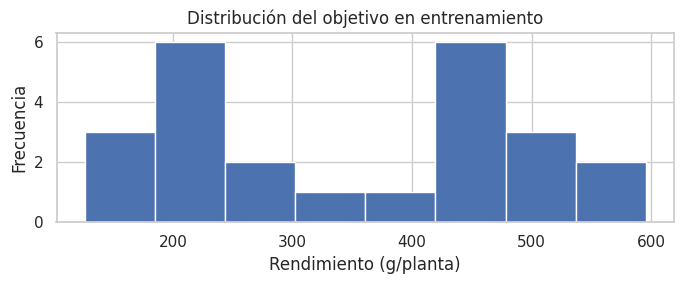

Atípicos IQR (objetivo, train): 0


In [9]:
TARGET = 'yield_g/planta'
assert TARGET in work.columns, f'Objetivo ausente: {TARGET}'
assert not work[['Cultivar','Treatment','Replicate']].duplicated().any()
assert set(tr.Parcel_ID).isdisjoint(set(te.Parcel_ID))
PRED_NUM = list(X_fe_cols)
PRED_CAT = ['Treatment_name', 'Cultivar']
PREDICTORS = PRED_NUM + PRED_CAT
assert TARGET not in PREDICTORS
train_data = tr.loc[tr[TARGET].notna()].copy()
test_data = te.loc[te[TARGET].notna()].copy()
print('Tarea: regresión | objetivo:', TARGET)
print('Train/test:', len(train_data), len(test_data), ' | parcelas:',train_data.Parcel_ID.nunique(),test_data.Parcel_ID.nunique())
print('Predictores numéricos:',len(PRED_NUM),' | categóricos:',PRED_CAT)
print('Faltantes en X train:',int(train_data[PREDICTORS].isna().sum().sum()))
print('Duplicados de clave:',int(work.duplicated(['Cultivar','Treatment','Replicate']).sum()))
print('Objetivo (train):');display(train_data[TARGET].describe().to_frame())
fig,ax=plt.subplots(figsize=(7,3));ax.hist(train_data[TARGET],bins=8,edgecolor='white');ax.set(xlabel='Rendimiento (g/planta)',ylabel='Frecuencia',title='Distribución del objetivo en entrenamiento');plt.tight_layout();plt.show()
# Auditoría descriptiva de atípicos (sin eliminarlos).
q1,q3=train_data[TARGET].quantile([.25,.75]);iqr=q3-q1
print('Atípicos IQR (objetivo, train):',int(((train_data[TARGET]<q1-1.5*iqr)|(train_data[TARGET]>q3+1.5*iqr)).sum()))

## 2. Diseño de evaluación sin fuga de información

- **Train/test:** se conserva `GroupShuffleSplit` del Avance 4. Donna y Dream de una misma parcela nunca se separan entre entrenamiento y prueba.
- **Validación externa:** `GroupKFold(4)` sobre las parcelas del conjunto de entrenamiento. Todos los candidatos usan exactamente los mismos folds.
- **Validación interna:** `GroupKFold(3)` para optimización de hiperparámetros.
- **Selección supervisada de variables:** permanece dentro de cada `Pipeline`; no se seleccionan variables utilizando el holdout.
- **Preprocesamiento:** imputación mediana, estandarización y One-Hot Encoding se ajustan solo con el fold de entrenamiento.
- **Categorías conocidas por diseño:** los niveles de tratamiento y cultivar se declaran explícitamente, por lo que la ausencia temporal de un tratamiento en un fold no genera una categoría desconocida.
- **Métrica primaria:** RMSE en g/planta. Como métricas secundarias se reportan MAE, R², desviación del RMSE, RMSE de entrenamiento y tiempo de entrenamiento.
- **Holdout:** se consulta una sola vez, después de elegir el modelo final con validación cruzada.

Los gráficos ROC, matriz de confusión y Precision-Recall son propios de clasificación y **no aplican** a este problema de regresión continua.


In [10]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import f_regression
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.exceptions import ConvergenceWarning
from time import perf_counter
import warnings

# Modificables; no cambiar después de consultar test.
CV_OUTER_FOLDS = 4
CV_INNER_FOLDS = 3
FEATURE_QUOTAS = (4,6,2)
HOLDOUT_EVAL = True  # ejecutar UNA sola vez después de fijar el diseño.

class ScientificSelector(BaseEstimator, TransformerMixin):
    def __init__(self, quotas=(4,6,2), numeric_cols=None, cat_cols=None):
        self.quotas=quotas;self.numeric_cols=numeric_cols;self.cat_cols=cat_cols
    def fit(self,X,y):
        selected=[]
        for prefix,k in zip(('soil','leaf','rgb'),self.quotas):
            if prefix=='soil':cols=[c for c in self.numeric_cols if c.startswith('soil_')]
            elif prefix=='rgb':cols=[c for c in self.numeric_cols if c.startswith(('leaf_rgb_','FE_delta_leaf_rgb_'))]
            else:cols=[c for c in self.numeric_cols if c.startswith(('leaf_','FE_delta_leaf_')) and not c.startswith(('leaf_rgb_','FE_delta_leaf_rgb_'))]
            cols=[c for c in cols if c in X.columns and X[c].notna().any()]
            if not cols or k==0:continue
            z=X[cols].apply(pd.to_numeric,errors='coerce');z=z.fillna(z.median())
            valid=[c for c in cols if z[c].notna().all() and z[c].nunique()>1]
            if not valid:continue
            with warnings.catch_warnings():
                warnings.simplefilter('ignore');scores,_=f_regression(z[valid],np.asarray(y).ravel())
            rank=pd.DataFrame({'feature':valid,'F':np.nan_to_num(scores,nan=-1,posinf=-1,neginf=-1)}).sort_values(['F','feature'],ascending=[False,True])
            selected+=rank.head(k).feature.tolist()
        self.selected_=list(dict.fromkeys(selected))
        if not self.selected_:raise ValueError('Sin predictores numéricos seleccionados.')
        return self
    def transform(self,X):return X.loc[:,self.selected_+self.cat_cols].copy()

def one_hot():
    try:
        return OneHotEncoder(categories=[TREATMENT_ORDER,['Donna','Dream']], drop=None, handle_unknown='ignore', sparse_output=False)
    except TypeError:
        return OneHotEncoder(categories=[TREATMENT_ORDER,['Donna','Dream']], drop=None, handle_unknown='ignore', sparse=False)

def pipeline_for(estimator):
    prep=ColumnTransformer([
        ('numeric',Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())]),make_column_selector(dtype_include=np.number)),
        ('categorical',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('ohe',one_hot())]),PRED_CAT)
    ],sparse_threshold=0)
    return Pipeline([('selector',ScientificSelector(quotas=FEATURE_QUOTAS,numeric_cols=PRED_NUM,cat_cols=PRED_CAT)),('prep',prep),('model',estimator)])

MODELS = {
 'Regresión lineal':LinearRegression(),
 'Ridge':Ridge(alpha=10.0),
 'Lasso':Lasso(alpha=1.0,max_iter=30000,random_state=SEED),
 'SVR':SVR(kernel='rbf',C=1.0,epsilon=0.1, gamma='scale'),
 'KNN':KNeighborsRegressor(n_neighbors=3,weights='uniform'),
 'Árbol de decisión':DecisionTreeRegressor(max_depth=2,min_samples_leaf=3,random_state=SEED),
}
X=train_data[PREDICTORS];y=train_data[TARGET].astype(float);groups=train_data.Parcel_ID
outer_cv=GroupKFold(n_splits=min(CV_OUTER_FOLDS,groups.nunique()))
scoring={'rmse':'neg_root_mean_squared_error','mae':'neg_mean_absolute_error','r2':'r2'}
print('Algoritmos individuales:',list(MODELS))


Algoritmos individuales: ['Regresión lineal', 'Ridge', 'Lasso', 'SVR', 'KNN', 'Árbol de decisión']


## 3. Modelos individuales de la fase previa y estrategia de ensamble

El Avance 4 evaluó seis regresores individuales: **Regresión lineal, Ridge, Lasso, SVR, KNN y Árbol de decisión**. En esta fase se conservan los seis en la tabla comparativa para que el beneficio —o ausencia de beneficio— de los ensambles sea observable directamente.

Los dos modelos individuales priorizados para la construcción de ensambles heterogéneos son **KNN y Ridge**. Ambos se vuelven a optimizar con las mismas grillas del Avance 4, pero únicamente dentro de los datos de entrenamiento de cada fold externo.

### Estrategias de ensamble
| Modelo | Estrategia | Idea |
|---|---|---|
| Bagging | Homogénea | Promedia múltiples árboles entrenados sobre remuestras. |
| Random Forest | Homogénea | Ensamble de árboles con aleatoriedad en muestras y variables. |
| Extra Trees | Homogénea | Ensamble de árboles con mayor aleatoriedad en los cortes. |
| Voting KNN + Ridge | Heterogénea | Promedia las predicciones de los dos mejores modelos individuales de la fase previa. |
| Stacking KNN + Ridge | Heterogénea | Usa predicciones out-of-fold de KNN y Ridge como entradas de un meta-modelo Ridge. |

La selección del modelo final no obliga a que un ensamble gane: si un modelo individual generaliza mejor, ese resultado se conserva.


In [11]:
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, ExtraTreesRegressor, VotingRegressor
from sklearn.model_selection import ParameterGrid
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.inspection import permutation_importance
import inspect

# Grillas idénticas a las usadas en Avance 4 para los dos mejores modelos individuales.
PARAM_GRIDS_INDIVIDUAL = {
    'KNN': {
        'model__n_neighbors':[2,3,4,5],
        'model__weights':['uniform','distance'],
        'model__p':[1,2],
        'selector__quotas':[(3,3,2),(4,6,2)]
    },
    'Ridge': {
        'model__alpha':[0.1,1,3,10,30,100,300,1000],
        'selector__quotas':[(3,3,2),(4,6,2),(5,8,3),(6,10,4)]
    }
}

BEST_PREVIOUS = ['KNN','Ridge']

# Espacios compactos: se optimiza complejidad sin inflar artificialmente la búsqueda con n≈24 en train.
ENSEMBLE_GRIDS = {
    'Bagging': {
        'n_estimators':[30,60],
        'max_samples':[10,12],
        'min_samples_leaf':[2],
        'selector_quotas':[(4,6,2)]
    },
    'Random Forest': {
        'n_estimators':[60,120],
        'max_depth':[2,4],
        'min_samples_leaf':[2],
        'max_features':[0.7],
        'selector_quotas':[(4,6,2)]
    },
    'Extra Trees': {
        'n_estimators':[60,120],
        'max_depth':[2,4],
        'min_samples_leaf':[2],
        'max_features':[0.7],
        'selector_quotas':[(4,6,2)]
    },
    'Voting KNN + Ridge': {
        'weights':[(1,1),(2,1),(1,2)]
    },
    'Stacking KNN + Ridge': {
        'meta_alpha':[1.0,10.0,100.0],
        'n_splits':[3]
    }
}


def tune_individual(name, X_fit, y_fit, groups_fit):
    """Optimiza KNN o Ridge respetando parcelas."""
    cv = GroupKFold(n_splits=min(CV_INNER_FOLDS, pd.Series(groups_fit).nunique()))
    search = GridSearchCV(
        pipeline_for(clone(MODELS[name])),
        PARAM_GRIDS_INDIVIDUAL[name],
        scoring='neg_root_mean_squared_error',
        cv=cv,
        n_jobs=-1,
        refit=True,
        error_score='raise'
    )
    start = perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        search.fit(X_fit, y_fit, groups=groups_fit)
    return search.best_estimator_, search.best_params_, -search.best_score_, perf_counter()-start


def pipeline_from_best(name, best_params):
    """Reconstruye KNN/Ridge con los parámetros óptimos de un fold."""
    if name == 'KNN':
        est = KNeighborsRegressor(
            n_neighbors=best_params['model__n_neighbors'],
            weights=best_params['model__weights'],
            p=best_params['model__p']
        )
    elif name == 'Ridge':
        est = Ridge(alpha=best_params['model__alpha'])
    else:
        raise KeyError(name)
    pipe = pipeline_for(est)
    pipe.set_params(selector__quotas=best_params['selector__quotas'])
    return pipe


class GroupStackingRegressor(BaseEstimator, RegressorMixin):
    """Stacking de KNN y Ridge con meta-modelo Ridge y OOF agrupado por parcela."""
    def __init__(self, knn_params=None, ridge_params=None, meta_alpha=10.0, n_splits=3):
        self.knn_params = knn_params
        self.ridge_params = ridge_params
        self.meta_alpha = meta_alpha
        self.n_splits = n_splits

    def _base_models(self):
        return [
            pipeline_from_best('KNN', self.knn_params),
            pipeline_from_best('Ridge', self.ridge_params)
        ]

    def fit(self, X, y, groups=None):
        if groups is None:
            raise ValueError('Stacking requiere groups=Parcel_ID para evitar fuga de información.')
        Xr = X.reset_index(drop=True)
        yr = pd.Series(np.asarray(y), dtype=float).reset_index(drop=True)
        gr = pd.Series(np.asarray(groups)).reset_index(drop=True)
        n_splits = min(self.n_splits, gr.nunique())
        cv = GroupKFold(n_splits=n_splits)
        oof = np.full((len(Xr), 2), np.nan)

        for a,b in cv.split(Xr, yr, gr):
            for j, est in enumerate(self._base_models()):
                est.fit(Xr.iloc[a], yr.iloc[a])
                oof[b,j] = np.asarray(est.predict(Xr.iloc[b])).ravel()

        if not np.isfinite(oof).all():
            raise ValueError('Stacking produjo predicciones OOF no finitas.')

        self.meta_ = Ridge(alpha=self.meta_alpha).fit(oof, yr)
        self.base_ = self._base_models()
        for est in self.base_:
            est.fit(Xr, yr)
        return self

    def predict(self, X):
        meta_X = np.column_stack([np.asarray(m.predict(X)).ravel() for m in self.base_])
        return self.meta_.predict(meta_X)


def make_bagging(n_estimators=50, max_samples=.8, min_samples_leaf=3):
    base = DecisionTreeRegressor(max_depth=3, min_samples_leaf=min_samples_leaf, random_state=SEED)
    kwargs = dict(n_estimators=n_estimators, max_samples=max_samples, random_state=SEED, n_jobs=-1)
    if 'estimator' in inspect.signature(BaggingRegressor).parameters:
        kwargs['estimator'] = base
    else:
        kwargs['base_estimator'] = base
    return BaggingRegressor(**kwargs)


def build_ensemble(name, params, knn_best, ridge_best):
    """Construye cada ensamble usando solo información del conjunto de entrenamiento correspondiente."""
    if name == 'Bagging':
        p = pipeline_for(make_bagging(params['n_estimators'], params['max_samples'], params['min_samples_leaf']))
        p.set_params(selector__quotas=params['selector_quotas'])
        return p
    if name == 'Random Forest':
        est = RandomForestRegressor(
            n_estimators=params['n_estimators'], max_depth=params['max_depth'],
            min_samples_leaf=params['min_samples_leaf'], max_features=params['max_features'],
            random_state=SEED, n_jobs=-1
        )
        p = pipeline_for(est); p.set_params(selector__quotas=params['selector_quotas']); return p
    if name == 'Extra Trees':
        est = ExtraTreesRegressor(
            n_estimators=params['n_estimators'], max_depth=params['max_depth'],
            min_samples_leaf=params['min_samples_leaf'], max_features=params['max_features'],
            random_state=SEED, n_jobs=-1
        )
        p = pipeline_for(est); p.set_params(selector__quotas=params['selector_quotas']); return p
    if name == 'Voting KNN + Ridge':
        return VotingRegressor(
            estimators=[
                ('knn', pipeline_from_best('KNN', knn_best)),
                ('ridge', pipeline_from_best('Ridge', ridge_best))
            ],
            weights=params['weights'], n_jobs=1
        )
    if name == 'Stacking KNN + Ridge':
        return GroupStackingRegressor(
            knn_params=knn_best, ridge_params=ridge_best,
            meta_alpha=params['meta_alpha'], n_splits=params['n_splits']
        )
    raise KeyError(name)


def fit_with_groups(estimator, name, X_fit, y_fit, groups_fit):
    if name == 'Stacking KNN + Ridge':
        estimator.fit(X_fit, y_fit, groups=groups_fit)
    else:
        estimator.fit(X_fit, y_fit)
    return estimator


def tune_ensemble(name, X_fit, y_fit, groups_fit, knn_best, ridge_best):
    """Grid manual con CV interna agrupada; devuelve modelo ajustado sobre todo X_fit."""
    cv = GroupKFold(n_splits=min(CV_INNER_FOLDS, pd.Series(groups_fit).nunique()))
    best_score = np.inf
    best_params = None
    start = perf_counter()

    for params in ParameterGrid(ENSEMBLE_GRIDS[name]):
        losses=[]
        for a,b in cv.split(X_fit, y_fit, groups_fit):
            est = build_ensemble(name, params, knn_best, ridge_best)
            est = fit_with_groups(est, name, X_fit.iloc[a], y_fit.iloc[a], groups_fit.iloc[a])
            pred = np.asarray(est.predict(X_fit.iloc[b])).ravel()
            losses.append(np.sqrt(mean_squared_error(y_fit.iloc[b], pred)))
        score = float(np.mean(losses))
        if score < best_score:
            best_score = score
            best_params = params

    fitted = build_ensemble(name, best_params, knn_best, ridge_best)
    fitted = fit_with_groups(fitted, name, X_fit, y_fit, groups_fit)
    return fitted, best_params, best_score, perf_counter()-start

print('Modelos individuales de Avance 4:', list(MODELS))
print('Mejores familias individuales usadas en Voting/Stacking:', BEST_PREVIOUS)
print('Ensambles:', list(ENSEMBLE_GRIDS))
print('Configuraciones de ensamble:', {k:len(list(ParameterGrid(v))) for k,v in ENSEMBLE_GRIDS.items()})


Modelos individuales de Avance 4: ['Regresión lineal', 'Ridge', 'Lasso', 'SVR', 'KNN', 'Árbol de decisión']
Mejores familias individuales usadas en Voting/Stacking: ['KNN', 'Ridge']
Ensambles: ['Bagging', 'Random Forest', 'Extra Trees', 'Voting KNN + Ridge', 'Stacking KNN + Ridge']
Configuraciones de ensamble: {'Bagging': 4, 'Random Forest': 4, 'Extra Trees': 4, 'Voting KNN + Ridge': 3, 'Stacking KNN + Ridge': 3}


## 4. Evaluación comparativa y optimización de hiperparámetros

La comparación se ejecuta con **los mismos folds externos para todos los modelos**. En cada fold:

1. KNN y Ridge se optimizan con CV interna agrupada.
2. Los otros cuatro modelos individuales de Avance 4 se ajustan con su configuración previa.
3. Los ensambles homogéneos optimizan sus hiperparámetros con CV interna.
4. Voting y Stacking reciben las configuraciones de KNN/Ridge obtenidas **solo con el train del fold externo**.
5. El fold externo se utiliza únicamente para estimar generalización.

Esto mantiene el holdout completamente aislado y permite comparar modelos individuales y ensambles bajo un protocolo común.


In [12]:
# Modelos a comparar: 6 individuales del Avance 4 + 5 ensambles.
INDIVIDUAL_NAMES = list(MODELS.keys())
ENSEMBLE_NAMES = list(ENSEMBLE_GRIDS.keys())
ALL_NAMES = INDIVIDUAL_NAMES + ENSEMBLE_NAMES

results_by_model = {name: [] for name in ALL_NAMES}
fold_rows = []
oof_predictions = {name: np.full(len(X), np.nan) for name in ALL_NAMES}

for fold, (idx_train, idx_val) in enumerate(outer_cv.split(X, y, groups), start=1):
    X_a, X_b = X.iloc[idx_train], X.iloc[idx_val]
    y_a, y_b = y.iloc[idx_train], y.iloc[idx_val]
    g_a = groups.iloc[idx_train]

    # Optimización de los dos mejores individuales de Avance 4 dentro del train externo.
    knn_fit, knn_params, knn_inner_rmse, knn_time = tune_individual('KNN', X_a, y_a, g_a)
    ridge_fit, ridge_params, ridge_inner_rmse, ridge_time = tune_individual('Ridge', X_a, y_a, g_a)

    # 1) Seis modelos individuales de la fase previa.
    for name in INDIVIDUAL_NAMES:
        start = perf_counter()
        if name == 'KNN':
            fitted = knn_fit; params = knn_params; tuning_time = knn_time
        elif name == 'Ridge':
            fitted = ridge_fit; params = ridge_params; tuning_time = ridge_time
        else:
            fitted = pipeline_for(clone(MODELS[name]))
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', ConvergenceWarning)
                fitted.fit(X_a, y_a)
            params = {'configuración':'Avance 4 sin optimización adicional'}
            tuning_time = perf_counter()-start

        pred_val = np.asarray(fitted.predict(X_b)).ravel()
        pred_train = np.asarray(fitted.predict(X_a)).ravel()
        rmse = np.sqrt(mean_squared_error(y_b, pred_val))
        mae = mean_absolute_error(y_b, pred_val)
        r2 = r2_score(y_b, pred_val) if y_b.nunique()>1 else np.nan
        rmse_train = np.sqrt(mean_squared_error(y_a, pred_train))
        oof_predictions[name][idx_val] = pred_val

        row = dict(Modelo=name, Tipo='Individual (Avance 4)', Estrategia='Individual', Fold=fold,
                   RMSE=rmse, MAE=mae, R2=r2, RMSE_train=rmse_train,
                   Tiempo_entrenamiento_s=tuning_time, Parametros=str(params))
        results_by_model[name].append(row); fold_rows.append(row)

    # 2) Ensambles. Voting/Stacking usan KNN y Ridge optimizados en este train externo.
    for name in ENSEMBLE_NAMES:
        fitted, params, inner_rmse, elapsed = tune_ensemble(
            name, X_a, y_a, g_a, knn_params, ridge_params
        )
        pred_val = np.asarray(fitted.predict(X_b)).ravel()
        pred_train = np.asarray(fitted.predict(X_a)).ravel()
        rmse = np.sqrt(mean_squared_error(y_b, pred_val))
        mae = mean_absolute_error(y_b, pred_val)
        r2 = r2_score(y_b, pred_val) if y_b.nunique()>1 else np.nan
        rmse_train = np.sqrt(mean_squared_error(y_a, pred_train))
        oof_predictions[name][idx_val] = pred_val

        strategy = 'Heterogéneo' if name in ['Voting KNN + Ridge','Stacking KNN + Ridge'] else 'Homogéneo'
        row = dict(Modelo=name, Tipo='Ensamble', Estrategia=strategy, Fold=fold,
                   RMSE=rmse, MAE=mae, R2=r2, RMSE_train=rmse_train,
                   Tiempo_entrenamiento_s=elapsed, Parametros=str(params))
        results_by_model[name].append(row); fold_rows.append(row)

# Resumen único solicitado por la rúbrica.
summary_rows=[]
for name in ALL_NAMES:
    d=pd.DataFrame(results_by_model[name])
    summary_rows.append({
        'Modelo':name,
        'Tipo':d['Tipo'].iloc[0],
        'Estrategia':d['Estrategia'].iloc[0],
        'RMSE_CV':d.RMSE.mean(),
        'RMSE_sd':d.RMSE.std(ddof=1),
        'MAE_CV':d.MAE.mean(),
        'R2_CV':d.R2.mean(),
        'RMSE_train':d.RMSE_train.mean(),
        'Gap_RMSE':d.RMSE.mean()-d.RMSE_train.mean(),
        'Tiempo_entrenamiento_s':d.Tiempo_entrenamiento_s.sum()
    })

comparison5 = pd.DataFrame(summary_rows).sort_values(['RMSE_CV','RMSE_sd']).reset_index(drop=True)
comparison5.insert(0, 'Posición', np.arange(1,len(comparison5)+1))

OUT5 = OUT / 'ensambles'
OUT5.mkdir(parents=True, exist_ok=True)
comparison5.to_csv(OUT5/'comparativa_modelos.csv', index=False)
pd.DataFrame(fold_rows).to_csv(OUT5/'resultados_por_fold.csv', index=False)

display(comparison5.round(3))


,Posición,Modelo,Tipo,Estrategia,RMSE_CV,RMSE_sd,MAE_CV,R2_CV,RMSE_train,Gap_RMSE,Tiempo_entrenamiento_s
0,1,Bagging,Ensamble,Homogéneo,52.526,14.899,42.889,0.871,41.991,10.535,3.590
1,2,Random Forest,Ensamble,Homogéneo,55.572,12.508,44.633,0.855,31.422,24.150,7.438
2,3,Extra Trees,Ensamble,Homogéneo,59.281,10.612,48.139,0.833,33.873,25.408,5.838
3,4,Voting KNN + Ridge,Ensamble,Heterogéneo,63.012,11.385,50.868,0.815,39.309,23.703,2.654
4,5,Ridge,Individual (Avance 4),Individual,63.438,13.608,49.413,0.814,28.058,35.379,2.606
5,6,Stacking KNN + Ridge,Ensamble,Heterogéneo,63.459,12.946,51.157,0.811,41.287,22.172,9.942
6,7,KNN,Individual (Avance 4),Individual,70.675,12.385,57.666,0.763,48.766,21.909,5.728
7,8,Árbol de decisión,Individual (Avance 4),Individual,72.287,14.840,58.230,0.739,35.203,37.084,0.111
8,9,Lasso,Individual (Avance 4),Individual,92.858,25.942,76.444,0.537,18.825,74.033,0.112
9,10,SVR,Individual (Avance 4),Individual,147.793,12.372,136.271,-0.013,146.769,1.024,0.110


## 5. Selección del modelo final y evaluación externa

La tabla anterior está ordenada por **RMSE CV**, la métrica primaria. Para alinear la selección con el objetivo de investigación y evitar elegir un modelo complejo por una diferencia mínima, se aplica la siguiente regla:

1. Se identifica el menor RMSE CV.
2. Se consideran competitivos los modelos cuyo RMSE esté dentro de **5%** del mejor.
3. Entre modelos competitivos se prioriza menor **RMSE_sd** (estabilidad entre parcelas).
4. Si la estabilidad es similar, se prioriza menor tiempo de entrenamiento y menor complejidad.

El holdout no interviene en esta elección. Solo después se entrena el ganador con todo el conjunto de entrenamiento y se evalúa una vez sobre las parcelas reservadas.


In [13]:
# Regla transparente de selección final.
best_rmse = comparison5['RMSE_CV'].min()
comparison5['Diferencia_vs_mejor_%'] = 100*(comparison5['RMSE_CV']/best_rmse - 1)
competitive = comparison5.loc[comparison5['Diferencia_vs_mejor_%'] <= 5].copy()

# Prioridad: estabilidad; después RMSE y tiempo.
selected_row = competitive.sort_values(['RMSE_sd','RMSE_CV','Tiempo_entrenamiento_s']).iloc[0]
winner = selected_row['Modelo']

print('Mejor RMSE CV absoluto:', comparison5.iloc[0]['Modelo'])
print('Modelos dentro de 5% del mejor:', competitive['Modelo'].tolist())
print('MODELO FINAL ELEGIDO:', winner)
print('Criterio: desempeño competitivo + estabilidad entre parcelas + costo computacional.')
display(comparison5.round(3))

# Optimizar KNN y Ridge en todo el train para alimentar al modelo final si corresponde.
knn_full, knn_full_params, _, knn_full_time = tune_individual('KNN', X, y, groups)
ridge_full, ridge_full_params, _, ridge_full_time = tune_individual('Ridge', X, y, groups)

start = perf_counter()
if winner == 'KNN':
    final5 = knn_full; final_params = knn_full_params
elif winner == 'Ridge':
    final5 = ridge_full; final_params = ridge_full_params
elif winner in [n for n in INDIVIDUAL_NAMES if n not in ['KNN','Ridge']]:
    final5 = pipeline_for(clone(MODELS[winner]))
    final5.fit(X,y)
    final_params = {'configuración':'Avance 4 sin optimización adicional'}
else:
    final5, final_params, _, _ = tune_ensemble(
        winner, X, y, groups, knn_full_params, ridge_full_params
    )
final_fit_time = perf_counter()-start

# Holdout externo: se consulta solo ahora.
Xt = test_data[PREDICTORS]
yt = test_data[TARGET].astype(float)
yhat = np.asarray(final5.predict(Xt)).ravel()

final_metrics = {
    'Modelo':winner,
    'RMSE_test':np.sqrt(mean_squared_error(yt,yhat)),
    'MAE_test':mean_absolute_error(yt,yhat),
    'R2_test':r2_score(yt,yhat),
    'Tiempo_entrenamiento_final_s':final_fit_time,
    'n_test':len(yt),
    'parcelas_test':test_data.Parcel_ID.nunique(),
    'Parametros_finales':str(final_params)
}

display(pd.DataFrame([final_metrics]).round(3))
pd.DataFrame([final_metrics]).to_csv(OUT5/'evaluacion_final.csv', index=False)
comparison5.to_csv(OUT5/'comparativa_modelos_con_seleccion.csv', index=False)


Mejor RMSE CV absoluto: Bagging
Modelos dentro de 5% del mejor: ['Bagging']
MODELO FINAL ELEGIDO: Bagging
Criterio: desempeño competitivo + estabilidad entre parcelas + costo computacional.


,Posición,Modelo,Tipo,Estrategia,RMSE_CV,RMSE_sd,MAE_CV,R2_CV,RMSE_train,Gap_RMSE,Tiempo_entrenamiento_s,Diferencia_vs_mejor_%
0,1,Bagging,Ensamble,Homogéneo,52.526,14.899,42.889,0.871,41.991,10.535,3.590,0.000
1,2,Random Forest,Ensamble,Homogéneo,55.572,12.508,44.633,0.855,31.422,24.150,7.438,5.799
2,3,Extra Trees,Ensamble,Homogéneo,59.281,10.612,48.139,0.833,33.873,25.408,5.838,12.860
3,4,Voting KNN + Ridge,Ensamble,Heterogéneo,63.012,11.385,50.868,0.815,39.309,23.703,2.654,19.963
4,5,Ridge,Individual (Avance 4),Individual,63.438,13.608,49.413,0.814,28.058,35.379,2.606,20.774
5,6,Stacking KNN + Ridge,Ensamble,Heterogéneo,63.459,12.946,51.157,0.811,41.287,22.172,9.942,20.814
6,7,KNN,Individual (Avance 4),Individual,70.675,12.385,57.666,0.763,48.766,21.909,5.728,34.553
7,8,Árbol de decisión,Individual (Avance 4),Individual,72.287,14.840,58.230,0.739,35.203,37.084,0.111,37.621
8,9,Lasso,Individual (Avance 4),Individual,92.858,25.942,76.444,0.537,18.825,74.033,0.112,76.785
9,10,SVR,Individual (Avance 4),Individual,147.793,12.372,136.271,-0.013,146.769,1.024,0.110,181.372


,Modelo,RMSE_test,MAE_test,R2_test,Tiempo_entrenamiento_final_s,n_test,parcelas_test,Parametros_finales
0,Bagging,63.627,46.694,0.763,0.917,8,4,"{'max_samples': 12, 'min_samples_leaf': 2, 'n_..."


## 6. Gráficos del modelo elegido e interpretación

Para regresión se utilizan visualizaciones alineadas con el tipo de problema:

1. **Comparación de RMSE** de todos los modelos individuales y ensambles.
2. **Observado vs. predicho** en el holdout.
3. **Residuos vs. predicción** para revisar sesgo y patrones sistemáticos.
4. **Error absoluto por observación** para detectar casos que concentran el error.
5. **Importancia por permutación** como aproximación exploratoria a la contribución predictiva.

La importancia por permutación no se interpreta causalmente y es inestable con solo ocho observaciones de prueba.


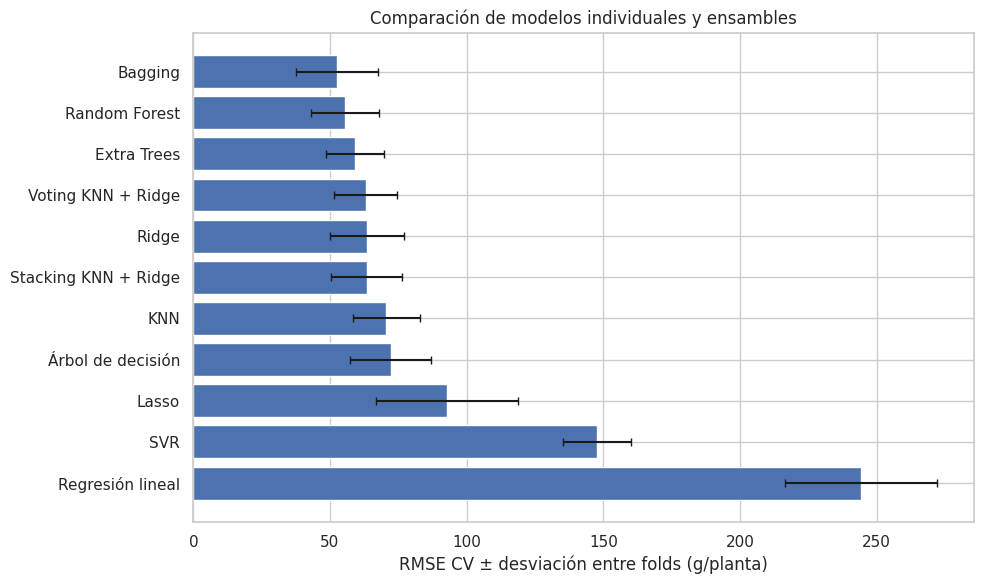

**Interpretación.** El menor RMSE CV corresponde a **Bagging** (52.53 g/planta). El modelo seleccionado por la regla de estabilidad es **Bagging**. La dispersión entre folds debe considerarse junto con el promedio por el tamaño reducido de la muestra.

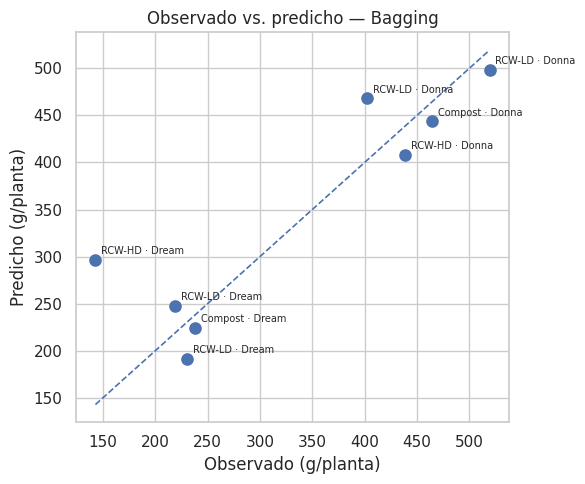

**Interpretación.** En prueba, **Bagging** obtiene RMSE=63.63, MAE=46.69 y R²=0.763. La cercanía a la diagonal representa mejor concordancia; las etiquetas permiten ubicar errores por tratamiento y cultivar.

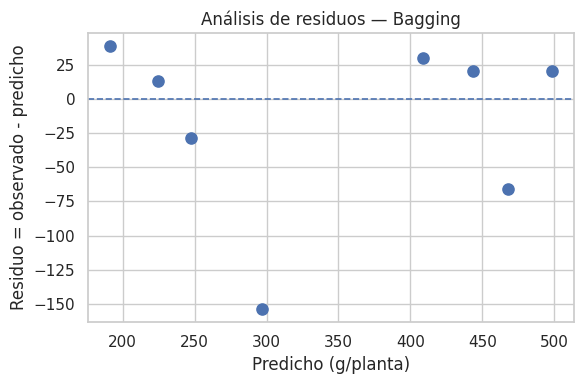

**Interpretación.** El residuo medio es **-15.40 g/planta**. Un patrón aleatorio alrededor de cero es deseable; con n=8 en prueba no es apropiado afirmar normalidad u homocedasticidad de forma concluyente.

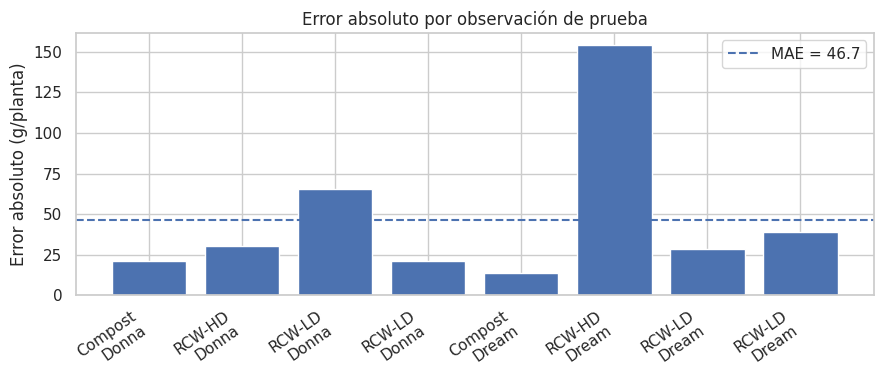

**Interpretación.** El mayor error absoluto ocurre en **RCW-HD · Dream** con 154.04 g/planta. Este caso debe revisarse en contexto antes de atribuirlo a una falla general del modelo.

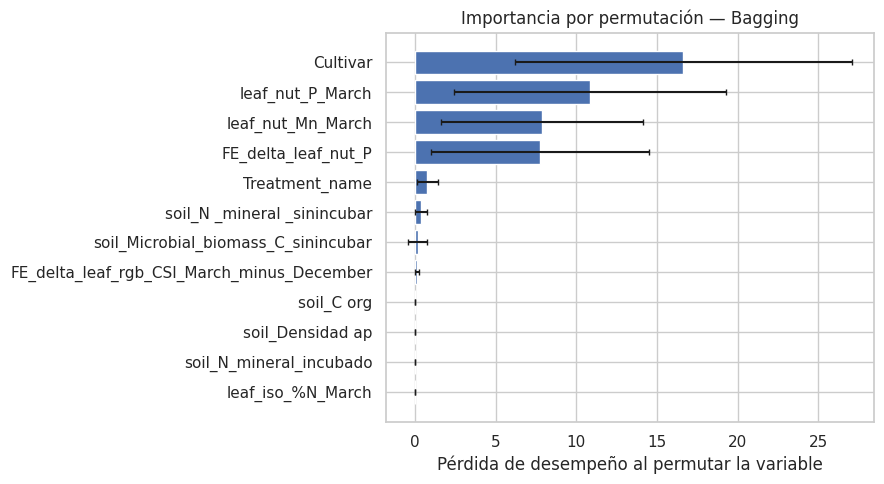

,Variable,Importancia_media,Importancia_sd
65,Cultivar,16.6366,10.4402
26,leaf_nut_P_March,10.8340,8.4201
22,leaf_nut_Mn_March,7.8698,6.2588
50,FE_delta_leaf_nut_P,7.7288,6.7521
64,Treatment_name,0.7520,0.6543
9,soil_N _mineral _sinincubar,0.3439,0.3617
4,soil_Microbial_biomass_C_sinincubar,0.1451,0.6040
58,FE_delta_leaf_rgb_CSI_March_minus_December,0.1073,0.1168
1,soil_C org,0.0000,0.0000
0,soil_Densidad ap,0.0000,0.0000


**Interpretación.** La variable con mayor importancia exploratoria es **Cultivar**. El ranking describe contribución predictiva en este holdout; no implica causalidad y debe interpretarse con cautela por el tamaño muestral.

In [14]:
# 1) Comparación de todos los modelos.
fig, ax = plt.subplots(figsize=(10,6))
ax.barh(comparison5['Modelo'], comparison5['RMSE_CV'], xerr=comparison5['RMSE_sd'], capsize=3)
ax.invert_yaxis()
ax.set_xlabel('RMSE CV ± desviación entre folds (g/planta)')
ax.set_title('Comparación de modelos individuales y ensambles')
plt.tight_layout(); plt.savefig(OUT5/'01_comparacion_modelos.png', dpi=180); plt.show()

best_abs = comparison5.iloc[0]
display(Markdown(
    f"**Interpretación.** El menor RMSE CV corresponde a **{best_abs['Modelo']}** "
    f"({best_abs['RMSE_CV']:.2f} g/planta). El modelo seleccionado por la regla de estabilidad es "
    f"**{winner}**. La dispersión entre folds debe considerarse junto con el promedio por el tamaño reducido de la muestra."
))

# 2) Observado vs predicho.
fig, ax = plt.subplots(figsize=(6,5))
ax.scatter(yt, yhat, s=65)
lims=[min(float(yt.min()),float(yhat.min())), max(float(yt.max()),float(yhat.max()))]
ax.plot(lims, lims, '--', linewidth=1.2)
for i,(obs,pred) in enumerate(zip(yt,yhat)):
    label=f"{test_data.iloc[i]['Treatment_name']} · {test_data.iloc[i]['Cultivar']}"
    ax.annotate(label, (obs,pred), xytext=(4,4), textcoords='offset points', fontsize=7)
ax.set_xlabel('Observado (g/planta)'); ax.set_ylabel('Predicho (g/planta)')
ax.set_title(f'Observado vs. predicho — {winner}')
plt.tight_layout(); plt.savefig(OUT5/'02_observado_predicho.png', dpi=180); plt.show()

display(Markdown(
    f"**Interpretación.** En prueba, **{winner}** obtiene RMSE={final_metrics['RMSE_test']:.2f}, "
    f"MAE={final_metrics['MAE_test']:.2f} y R²={final_metrics['R2_test']:.3f}. "
    "La cercanía a la diagonal representa mejor concordancia; las etiquetas permiten ubicar errores por tratamiento y cultivar."
))

# 3) Residuos.
resid = np.asarray(yt) - yhat
fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(yhat, resid, s=65)
ax.axhline(0, linestyle='--', linewidth=1.2)
ax.set_xlabel('Predicho (g/planta)'); ax.set_ylabel('Residuo = observado - predicho')
ax.set_title(f'Análisis de residuos — {winner}')
plt.tight_layout(); plt.savefig(OUT5/'03_residuos.png', dpi=180); plt.show()

bias=float(np.mean(resid))
display(Markdown(
    f"**Interpretación.** El residuo medio es **{bias:.2f} g/planta**. "
    "Un patrón aleatorio alrededor de cero es deseable; con n=8 en prueba no es apropiado afirmar normalidad u homocedasticidad de forma concluyente."
))

# 4) Error absoluto por observación.
labels=[f"{r.Treatment_name}\n{r.Cultivar}" for _,r in test_data.reset_index(drop=True).iterrows()]
abs_error=np.abs(resid)
fig, ax = plt.subplots(figsize=(9,4))
ax.bar(np.arange(len(abs_error)), abs_error)
ax.axhline(abs_error.mean(), linestyle='--', label=f'MAE = {abs_error.mean():.1f}')
ax.set_xticks(np.arange(len(labels))); ax.set_xticklabels(labels, rotation=35, ha='right')
ax.set_ylabel('Error absoluto (g/planta)'); ax.set_title('Error absoluto por observación de prueba')
ax.legend(); plt.tight_layout(); plt.savefig(OUT5/'04_error_absoluto.png', dpi=180); plt.show()

worst=int(np.argmax(abs_error))
display(Markdown(
    f"**Interpretación.** El mayor error absoluto ocurre en **{labels[worst].replace(chr(10),' · ')}** "
    f"con {abs_error[worst]:.2f} g/planta. Este caso debe revisarse en contexto antes de atribuirlo a una falla general del modelo."
))

# 5) Importancia por permutación sobre las columnas originales de entrada.
imp = permutation_importance(
    final5, Xt, yt, n_repeats=20, random_state=SEED,
    scoring='neg_root_mean_squared_error', n_jobs=1
)
importance = pd.DataFrame({
    'Variable':Xt.columns,
    'Importancia_media':imp.importances_mean,
    'Importancia_sd':imp.importances_std
}).sort_values('Importancia_media', ascending=False).head(12)

fig, ax = plt.subplots(figsize=(9,5))
show=importance.sort_values('Importancia_media')
ax.barh(show['Variable'], show['Importancia_media'], xerr=show['Importancia_sd'], capsize=2)
ax.set_xlabel('Pérdida de desempeño al permutar la variable')
ax.set_title(f'Importancia por permutación — {winner}')
plt.tight_layout(); plt.savefig(OUT5/'05_importancia_permutacion.png', dpi=180); plt.show()

display(importance.round(4))
if len(importance):
    display(Markdown(
        f"**Interpretación.** La variable con mayor importancia exploratoria es **{importance.iloc[0]['Variable']}**. "
        "El ranking describe contribución predictiva en este holdout; no implica causalidad y debe interpretarse con cautela por el tamaño muestral."
    ))


## 7. Síntesis de cumplimiento de la actividad

| Requisito | Evidencia en la libreta |
|---|---|
| Variedad de modelos de ensamble | Bagging, Random Forest, Extra Trees, Voting y Stacking. |
| Ensamble homogéneo | Bagging, Random Forest y Extra Trees. |
| Ensamble heterogéneo | Voting KNN+Ridge y Stacking KNN+Ridge. |
| Optimización de hiperparámetros | CV interna agrupada para KNN, Ridge y todos los ensambles relevantes. |
| Stacking/Voting con mejores individuales previos | KNN y Ridge, reoptimizados únicamente con train en cada fold. |
| Comparación con fase previa | Los seis modelos individuales de Avance 4 aparecen en la misma tabla que los ensambles. |
| Orden por métrica principal | Tabla ordenada por RMSE CV. |
| Otras métricas | MAE, R², desviación de RMSE, RMSE train y gap de generalización. |
| Tiempo de entrenamiento | Se registra tiempo acumulado por modelo. |
| Modelo final alineado al objetivo | Regla explícita basada en RMSE, estabilidad y costo; holdout no participa en la elección. |
| Gráficos significativos | Comparación, observado-predicho, residuos, error absoluto e importancia por permutación. |
| Sin gráficos de clasificación inadecuados | ROC, Precision-Recall y matriz de confusión se excluyen por tratarse de regresión. |

### Limitaciones
- Solo existen 16 parcelas y 32 observaciones analíticas.
- La evaluación externa contiene pocas parcelas; las métricas pueden variar con nuevas temporadas.
- La selección de variables es supervisada y se realiza dentro de cada fold para evitar fuga, pero el tamaño de muestra limita estabilidad.
- El análisis es predictivo y asociativo; no demuestra causalidad de tratamiento, suelo o nutrición sobre el rendimiento.


In [15]:
# Exportación y controles finales de reproducibilidad.
importance.to_csv(OUT5/'importancia_permutacion.csv', index=False)

checks = pd.DataFrame([
    {'Control':'32 observaciones analíticas', 'Cumple':len(work)==32},
    {'Control':'16 parcelas', 'Cumple':work.Parcel_ID.nunique()==16},
    {'Control':'Sin overlap train/test por parcela', 'Cumple':set(train_data.Parcel_ID).isdisjoint(set(test_data.Parcel_ID))},
    {'Control':'6 modelos individuales incluidos', 'Cumple':sum(comparison5.Estrategia.eq('Individual'))==6},
    {'Control':'Ensambles homogéneos incluidos', 'Cumple':sum(comparison5.Estrategia.eq('Homogéneo'))>=3},
    {'Control':'Ensambles heterogéneos incluidos', 'Cumple':sum(comparison5.Estrategia.eq('Heterogéneo'))>=2},
    {'Control':'Tabla ordenada por RMSE', 'Cumple':comparison5.RMSE_CV.is_monotonic_increasing},
    {'Control':'Tiempo de entrenamiento reportado', 'Cumple':comparison5.Tiempo_entrenamiento_s.notna().all()},
])
display(checks)
checks.to_csv(OUT5/'controles_calidad.csv', index=False)

print('Archivos exportados en:', OUT5)
print('Modelo final:', winner)


,Control,Cumple
0,32 observaciones analíticas,True
1,16 parcelas,True
2,Sin overlap train/test por parcela,True
3,6 modelos individuales incluidos,True
4,Ensambles homogéneos incluidos,True
5,Ensambles heterogéneos incluidos,True
6,Tabla ordenada por RMSE,True
7,Tiempo de entrenamiento reportado,True


Archivos exportados en: /mnt/data/outputs/avance5_modelado/ensambles
Modelo final: Bagging


## Declaración de uso de herramientas de inteligencia artificial

Durante la elaboración de esta libreta, el **Equipo 54**, integrado por **Fanny Betsabé Fuentes Reyes, Juan Luis Ramírez Sánchez y Joaquín Rincón Pérez**, utilizó herramientas de inteligencia artificial generativa como apoyo para la estructuración del flujo analítico, revisión de código, depuración, documentación y discusión metodológica.

Se utilizó **ChatGPT de OpenAI** como apoyo para revisar la arquitectura de la libreta, proponer alternativas de implementación de modelos de ensamble, verificar criterios de validación y mejorar la claridad de las explicaciones. También se utilizó **GitHub Copilot** como apoyo en actividades de edición y gestión del código dentro del repositorio.

Las herramientas de inteligencia artificial **no generaron, modificaron ni sustituyeron los datos experimentales**. Los resultados numéricos mostrados en esta libreta se obtienen mediante la ejecución del código sobre los archivos proporcionados para el proyecto. La selección de métodos, revisión de resultados, interpretación, conclusiones y responsabilidad académica del trabajo corresponden a los integrantes del equipo.

**Referencia de la herramienta principal:** OpenAI. (2026). *ChatGPT* [Modelo de lenguaje de gran escala]. https://chatgpt.com/
